# Entrega 2 — Árbol de decisión | Nicole · Grupo 19



## 1. Carga y validación de datos

Configurar `RUTA_CSV` con la ruta del archivo consolidado si no se encuentra automáticamente.


In [0]:
from pathlib import Path
import json, warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
RUTA_CSV = '/Workspace/Users/nv.ninoh1@uniandes.edu.co/Drafts/ELCO_2022_creditos_ahorro_laboral_consolidado.csv'
NOMBRE_CSV = 'ELCO_2022_creditos_ahorro_laboral_consolidado.csv'
ROOT = Path.cwd()
CANDIDATOS = [ROOT / NOMBRE_CSV, ROOT / 'data' / NOMBRE_CSV,
              ROOT / 'files' / NOMBRE_CSV, ROOT / 'entrega_elco' / NOMBRE_CSV,
              Path('/dbfs/FileStore') / NOMBRE_CSV]
RUTA = Path(RUTA_CSV) if RUTA_CSV.strip() else next((q for q in CANDIDATOS if q.is_file()), None)
if RUTA is None or not RUTA.is_file():
    raise FileNotFoundError('No se encontró el CSV. Súbelo a Databricks y especifica su ruta en RUTA_CSV.')
OUT = Path('/tmp/resultados_arbol_Nicole') if os.environ.get('DATABRICKS_RUNTIME_VERSION') else ROOT / 'resultados_arbol_Nicole'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(RUTA)
obligatorias = ['DIRECTORIO','objetivo_atraso','P2110']
assert set(obligatorias).issubset(df.columns), f'Faltan columnas: {set(obligatorias)-set(df.columns)}'
assert len(df) == 4013 and df.DIRECTORIO.nunique() == 3020, 'Versión de datos distinta: confirmar con el equipo.'
assert df['objetivo_atraso'].isin([0, 1]).all()
assert (df['objetivo_atraso'] == (df['P2110'] == 2).astype(int)).all()
print('Archivo:', RUTA)
print('Créditos:', len(df), '| Hogares:', df.DIRECTORIO.nunique(), '| Retrasos:', int(df.objetivo_atraso.sum()))
print('Resultados:', OUT)

Archivo: /Workspace/Users/nv.ninoh1@uniandes.edu.co/Drafts/ELCO_2022_creditos_ahorro_laboral_consolidado.csv
Créditos: 4013 | Hogares: 3020 | Retrasos: 675
Resultados: /tmp/resultados_arbol_Nicole


## 2. Selección de variables

`P2110` es la variable objetivo; `DIRECTORIO` y `P2108` no son predictores.


In [0]:
CATEGORICAS = ['P2097','P2098','P2106']
NUMERICAS_A = ['P2099S2','P2104','P2105S1','P2107S1']
HOGAR = ['n_personas_ahorro','n_personas_con_ingresos','n_personas_que_ahorran',
         'prop_que_ahorran_sobre_con_ingresos','n_personas_con_cuenta',
         'n_personas_laboral','n_personas_trabajo_semana']
VARIABLES_A = CATEGORICAS + NUMERICAS_A
VARIABLES_B = VARIABLES_A + HOGAR
assert set(VARIABLES_B).issubset(df.columns), f'Faltan variables: {set(VARIABLES_B)-set(df.columns)}'
assert not {'P2110','P2108','DIRECTORIO'}.intersection(VARIABLES_B)
base = df.copy()
base['P2107S1'] = pd.to_numeric(base['P2107S1'], errors='coerce').replace(9999, np.nan)
for c in [x for x in VARIABLES_B if x not in CATEGORICAS]:
    base[c] = pd.to_numeric(base[c], errors='coerce')
for c in CATEGORICAS:
    base[c] = base[c].astype('string').astype(object).where(base[c].notna(), np.nan)
print('Variables A:', VARIABLES_A)
print('Variables B adicionales:', HOGAR)
print('Faltantes:\n', base[VARIABLES_B].isna().sum().loc[lambda x:x>0].to_string())

Variables A: ['P2097', 'P2098', 'P2106', 'P2099S2', 'P2104', 'P2105S1', 'P2107S1']
Variables B adicionales: ['n_personas_ahorro', 'n_personas_con_ingresos', 'n_personas_que_ahorran', 'prop_que_ahorran_sobre_con_ingresos', 'n_personas_con_cuenta', 'n_personas_laboral', 'n_personas_trabajo_semana']
Faltantes:
 P2105S1                                135
P2107S1                                128
prop_que_ahorran_sobre_con_ingresos    163


## 3. División de datos por hogar

Los hogares no se comparten entre entrenamiento, validación y prueba.


In [0]:
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
i_train, i_temp = next(gss.split(base, base.objetivo_atraso, groups=base.DIRECTORIO))
train = base.iloc[i_train].copy()
temporal = base.iloc[i_temp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED+1)
i_val, i_test = next(gss2.split(temporal, temporal.objetivo_atraso, groups=temporal.DIRECTORIO))
val = temporal.iloc[i_val].copy()
test = temporal.iloc[i_test].copy()
for x, y in [(train, val),(train, test),(val, test)]:
    assert set(x.DIRECTORIO).isdisjoint(set(y.DIRECTORIO))
for nombre, parte in [('Train',train),('Validación',val),('Prueba',test)]:
    assert set(parte.objetivo_atraso)=={0,1}, f'Falta una clase en {nombre}'
    print(f'{nombre}: {len(parte)} créditos; {parte.DIRECTORIO.nunique()} hogares; atraso={parte.objetivo_atraso.mean():.3f}')
y_train = train.objetivo_atraso.astype(int)
y_val = val.objetivo_atraso.astype(int)
y_test = test.objetivo_atraso.astype(int)

Train: 2808 créditos; 2114 hogares; atraso=0.173
Validación: 613 créditos; 453 hogares; atraso=0.153
Prueba: 592 créditos; 453 hogares; atraso=0.160


## 4. Entrenamiento y experimentos

Se comparan seis modelos con profundidades 3, 5 y 10; el preprocesamiento se ajusta en entrenamiento.


In [0]:
def crear_arbol(variables, profundidad):
    cats = [c for c in CATEGORICAS if c in variables]
    nums = [c for c in variables if c not in cats]
    pre = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median', add_indicator=True))]), nums),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cats)
    ])
    tree = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=5,
                                  class_weight='balanced', random_state=SEED)
    return Pipeline([('preparacion',pre),('modelo',tree)])

umbrales = np.round(np.arange(.10,.91,.05),2)
modelos, especificaciones, registros = {}, {}, []
for grupo, variables in [('A',VARIABLES_A),('B',VARIABLES_B)]:
    for profundidad in [3, 5, 10]:
        nombre = f'{grupo}_arbol_prof_{profundidad}'
        pipe = crear_arbol(variables, profundidad)
        pipe.fit(train[variables],y_train)
        p_val = pipe.predict_proba(val[variables])[:,1]
        f1_umbrales = [f1_score(y_val, (p_val>=u).astype(int), zero_division=0) for u in umbrales]
        umbral = float(umbrales[int(np.argmax(f1_umbrales))])
        pred_val = (p_val>=umbral).astype(int)
        registros.append({'experimento':nombre,'variables':grupo,'max_depth':profundidad,
                          'umbral_validacion':umbral,
                          'pr_auc_validacion':average_precision_score(y_val,p_val),
                          'roc_auc_validacion':roc_auc_score(y_val,p_val),
                          'precision_validacion':precision_score(y_val,pred_val,zero_division=0),
                          'recall_validacion':recall_score(y_val,pred_val,zero_division=0),
                          'f1_validacion':f1_score(y_val,pred_val,zero_division=0)})
        modelos[nombre] = pipe
        especificaciones[nombre] = variables
resultados_val = pd.DataFrame(registros).sort_values('pr_auc_validacion',ascending=False).reset_index(drop=True)
resultados_val.to_csv(OUT/'experimentos_validacion.csv',index=False)
print(resultados_val.round(4).to_string(index=False))

    experimento variables  max_depth  umbral_validacion  pr_auc_validacion  roc_auc_validacion  precision_validacion  recall_validacion  f1_validacion
 A_arbol_prof_5         A          5               0.60             0.3685              0.7378                0.3784             0.5957         0.4628
 B_arbol_prof_5         B          5               0.60             0.3627              0.7253                0.3567             0.6489         0.4604
A_arbol_prof_10         A         10               0.60             0.3465              0.7186                0.3609             0.5106         0.4229
B_arbol_prof_10         B         10               0.60             0.3229              0.7129                0.3529             0.5745         0.4372
 A_arbol_prof_3         A          3               0.65             0.2873              0.7033                0.3933             0.3723         0.3825
 B_arbol_prof_3         B          3               0.65             0.2873              0.7033

## 5. Selección del modelo y evaluación final

La selección y el umbral se fijan en validación; prueba se reserva para evaluación final.


GANADOR (seleccionado por validación): A_arbol_prof_5
modelo               A_arbol_prof_5
umbral_validacion               0.6
precision_test             0.289474
recall_test                0.463158
f1_test                    0.356275
pr_auc_test                0.341996
roc_auc_test               0.689262


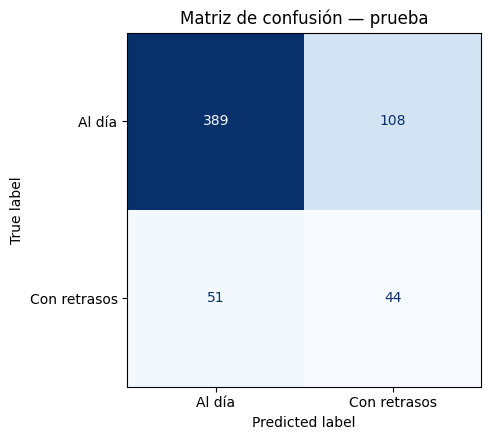

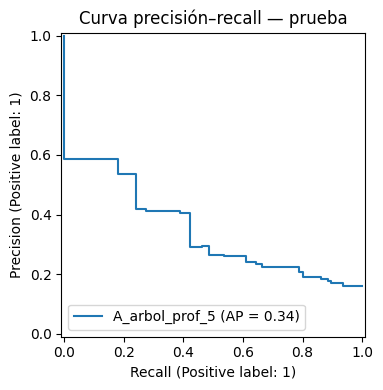

In [0]:
elegido = str(resultados_val.iloc[0]['experimento'])
mejor_val = resultados_val.iloc[0]
modelo_final = modelos[elegido]
vars_final = especificaciones[elegido]
umbral_final = float(mejor_val['umbral_validacion'])
proba_test = modelo_final.predict_proba(test[vars_final])[:,1]
pred_test = (proba_test>=umbral_final).astype(int)
metricas_test = {'modelo':elegido,'umbral_validacion':umbral_final,
                 'precision_test':precision_score(y_test,pred_test,zero_division=0),
                 'recall_test':recall_score(y_test,pred_test,zero_division=0),
                 'f1_test':f1_score(y_test,pred_test,zero_division=0),
                 'pr_auc_test':average_precision_score(y_test,proba_test),
                 'roc_auc_test':roc_auc_score(y_test,proba_test)}
print('GANADOR (seleccionado por validación):', elegido)
print(pd.Series(metricas_test).to_string())
pd.DataFrame([metricas_test]).to_csv(OUT/'modelo_ganador_prueba.csv',index=False)
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test,pred_test,labels=[0,1]),
                       display_labels=['Al día','Con retrasos']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Matriz de confusión — prueba')
plt.tight_layout();plt.savefig(OUT/'matriz_confusion_arbol.png',dpi=170);plt.show()
fig, ax = plt.subplots(figsize=(6,4))
PrecisionRecallDisplay.from_predictions(y_test,proba_test,ax=ax,name=elegido)
ax.set_title('Curva precisión–recall — prueba')
plt.tight_layout();plt.savefig(OUT/'curva_precision_recall_arbol.png',dpi=170);plt.show()

## 6. Comparación de métricas


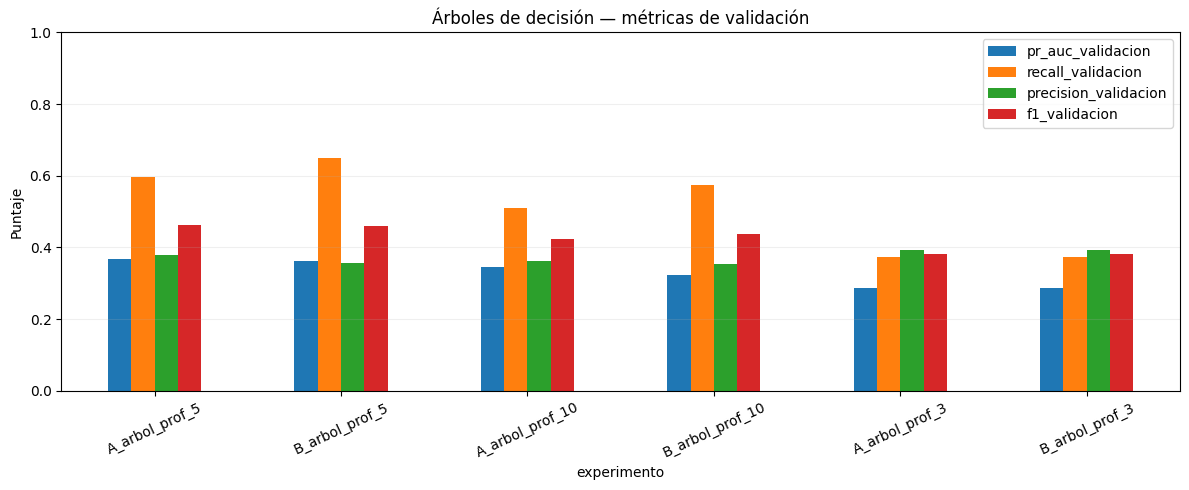

In [0]:
ax = resultados_val.set_index('experimento')[['pr_auc_validacion','recall_validacion','precision_validacion','f1_validacion']].plot(kind='bar',figsize=(12,5),ylim=(0,1),rot=25)
ax.set_title('Árboles de decisión — métricas de validación')
ax.set_ylabel('Puntaje');ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'comparacion_validacion_arbol.png',dpi=170);plt.show()

## 7. Diagrama del árbol de decisión

La visualización muestra los primeros tres niveles del modelo seleccionado.


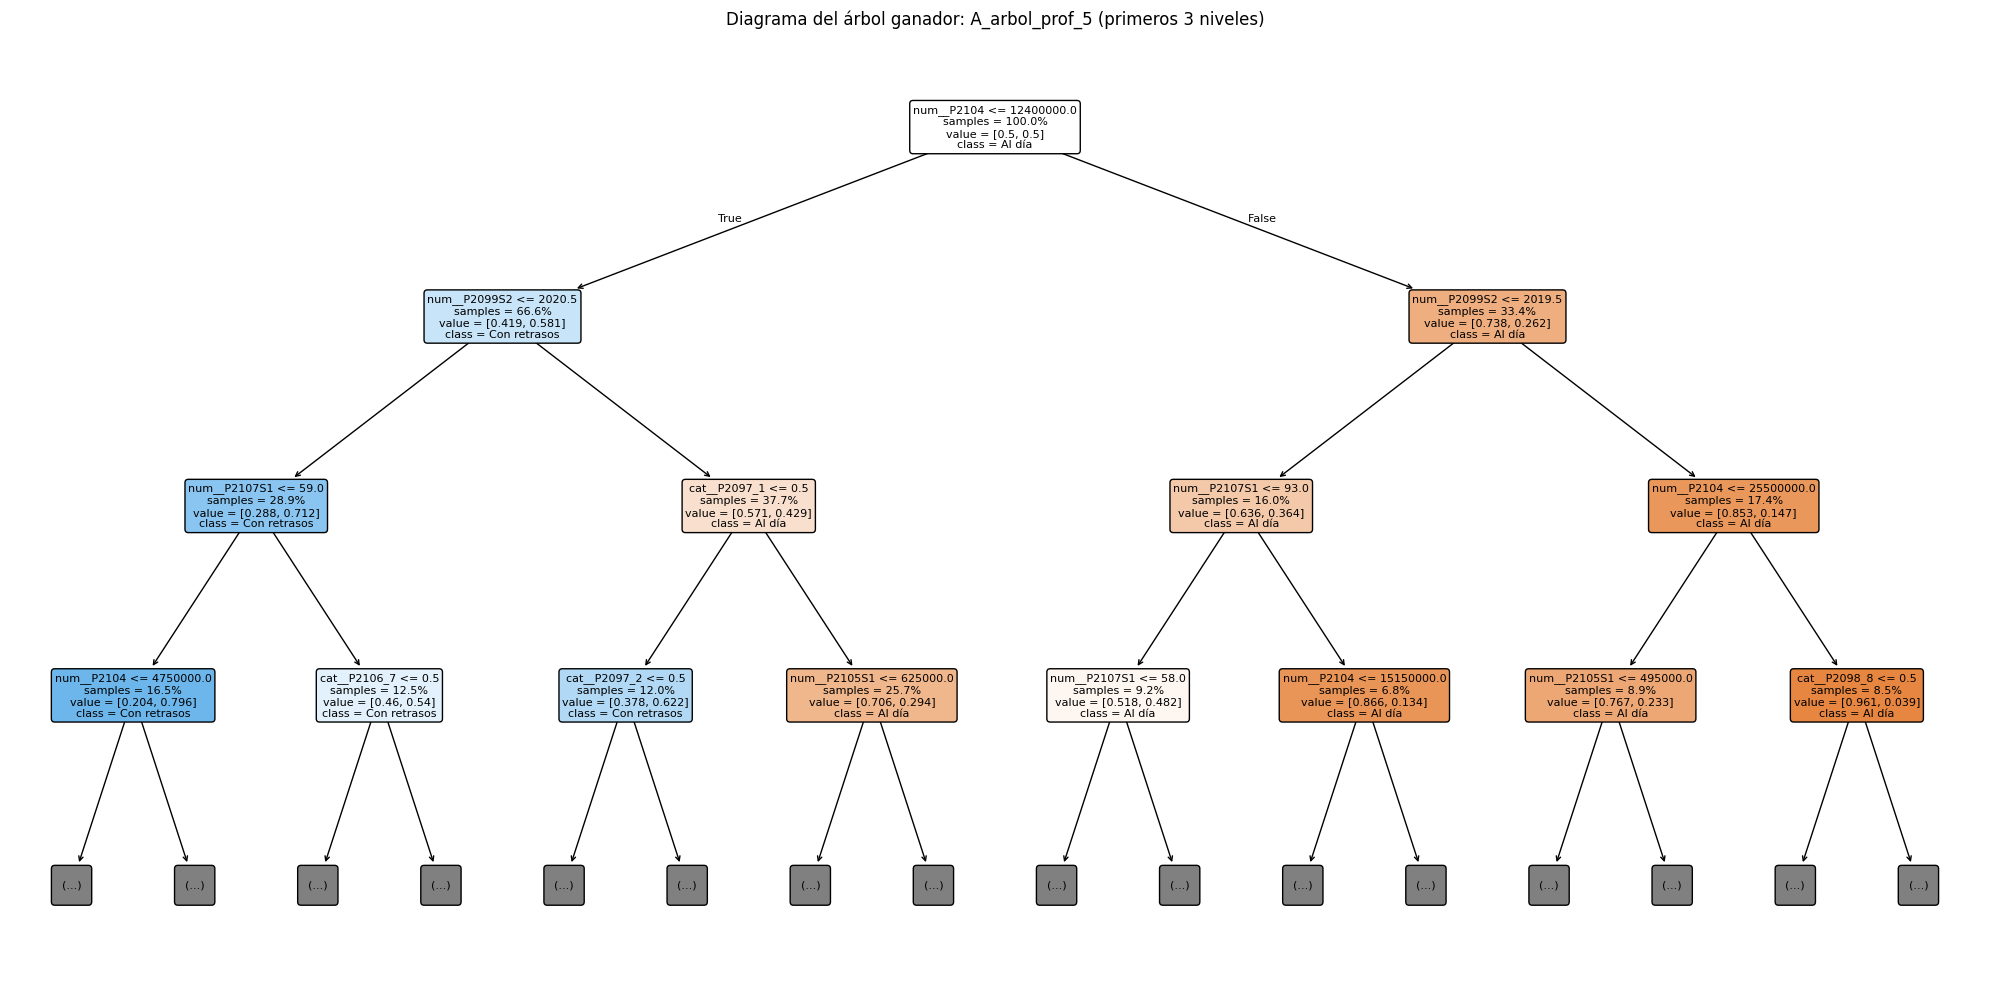

|--- num__P2104 <= 12400000.00
|   |--- num__P2099S2 <= 2020.50
|   |   |--- num__P2107S1 <= 59.00
|   |   |   |--- num__P2104 <= 4750000.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__P2104 >  4750000.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- num__P2107S1 >  59.00
|   |   |   |--- cat__P2106_7 <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- cat__P2106_7 >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- num__P2099S2 >  2020.50
|   |   |--- cat__P2097_1 <= 0.50
|   |   |   |--- cat__P2097_2 <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- cat__P2097_2 >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- cat__P2097_1 >  0.50
|   |   |   |--- num__P2105S1 <= 625000.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__P2105S1 >  625000.00
|   |   |   |   |--- truncated branch of depth 2
|--- num__P2104 >  12400000.00
|   |--- num__P2099S

In [0]:
pre = modelo_final.named_steps['preparacion']
arbol = modelo_final.named_steps['modelo']
try:
    nombres = pre.get_feature_names_out().tolist()
except Exception:
    nombres = [f'variable_{i}' for i in range(arbol.n_features_in_)]
fig, ax = plt.subplots(figsize=(20,10))
plot_tree(arbol, feature_names=nombres, class_names=['Al día','Con retrasos'],
          filled=True, rounded=True, impurity=False, proportion=True,
          max_depth=3, fontsize=8, ax=ax)
ax.set_title(f'Diagrama del árbol ganador: {elegido} (primeros 3 niveles)')
plt.tight_layout();plt.savefig(OUT/'diagrama_arbol.png',dpi=180,bbox_inches='tight');plt.show()
reglas = export_text(arbol,feature_names=nombres,max_depth=3)
print(reglas)
(OUT/'reglas_arbol.txt').write_text(reglas,encoding='utf-8')
importancias = pd.Series(arbol.feature_importances_,index=nombres).sort_values(ascending=False)
print('Variables transformadas con mayor importancia:\n',importancias.head(15).round(4).to_string())
importancias.to_csv(OUT/'importancia_variables_arbol.csv',header=['importancia'])

## 8. Exportación del modelo

Se guarda el árbol de decisión sin sobrescribir el modelo del equipo.


In [0]:
joblib.dump(modelo_final,OUT/'modelo_arbol_Nicole.joblib')
contrato = {'modelo':elegido,'algoritmo':'DecisionTreeClassifier',
            'variables_en_orden':vars_final,
            'categoricas':[c for c in CATEGORICAS if c in vars_final],
            'numericas':[c for c in vars_final if c not in CATEGORICAS],
            'umbral':umbral_final,'clase_positiva':1,
            'interpretacion':'Puntaje de clase con retrasos; uso académico orientativo',
            'datos':'ELCO 2022; separación por hogar; semilla 42',
            'ruta_modelo':'modelo_arbol_Nicole.joblib'}
(OUT/'contrato_arbol_Nicole.json').write_text(json.dumps(contrato,ensure_ascii=False,indent=2),encoding='utf-8')
print('Archivos generados:')
for archivo in sorted(OUT.iterdir()): print(' -',archivo)
print('ATENCIÓN: los archivos bajo /tmp/ en Databricks pueden ser temporales; descárgalos o cópialos a un volumen persistente.')

Archivos generados:
 - /tmp/resultados_arbol_Nicole/comparacion_validacion_arbol.png
 - /tmp/resultados_arbol_Nicole/contrato_arbol_Nicole.json
 - /tmp/resultados_arbol_Nicole/curva_precision_recall_arbol.png
 - /tmp/resultados_arbol_Nicole/diagrama_arbol.png
 - /tmp/resultados_arbol_Nicole/experimentos_validacion.csv
 - /tmp/resultados_arbol_Nicole/importancia_variables_arbol.csv
 - /tmp/resultados_arbol_Nicole/matriz_confusion_arbol.png
 - /tmp/resultados_arbol_Nicole/modelo_arbol_Nicole.joblib
 - /tmp/resultados_arbol_Nicole/modelo_ganador_prueba.csv
 - /tmp/resultados_arbol_Nicole/reglas_arbol.txt
ATENCIÓN: los archivos bajo /tmp/ en Databricks pueden ser temporales; descárgalos o cópialos a un volumen persistente.


## 9. Registro de experimentos en MLflow


In [0]:
try:
    import mlflow
    for _, fila in resultados_val.iterrows():
        with mlflow.start_run(run_name=str(fila['experimento'])):
            mlflow.log_params({'algoritmo':'DecisionTreeClassifier',
                               'grupo':str(fila['variables']),
                               'max_depth':int(fila['max_depth']),
                               'min_samples_leaf':5, 'semilla':SEED})
            for campo in ['umbral_validacion','pr_auc_validacion','roc_auc_validacion',
                          'precision_validacion','recall_validacion','f1_validacion']:
                mlflow.log_metric(campo,float(fila[campo]))
    print('Registrados seis experimentos de validación en MLflow.')
except Exception as error:
    print('MLflow no disponible o sin permisos. Los resultados CSV siguen guardados.')
    print(type(error).__name__, str(error)[:350])

{"ts": "2026-11-08 17:14:20.336", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvMTYwNzYyNDU1NDYwNDE4EAEgATIkMDFhMWJjMjYtZWJmOC03NTI2LWFmMTMtN2UyNmIzOThiZDljOiQ0YmE1YTA3Mi05NTUwLTNhMmYtOWIwYS01OGYwZjQ0ODRkOWVKDAjN28LXBhCA2IyFA1ABWAFgAWiM5Y7jgcWjDYgBAA==.", "context": {}}
{"ts": "2026-11-08 17:14:20.336", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvMTYwNzYyNDU1NDYwNDE4EAEgATIkMDFhMWJjMjYtZWJmOC03NTI2LWFmMTMtN2UyNmIzOThiZDljOiQ0YmE1YTA3Mi05NTUwLTNhMmYtOWIwYS01OGYwZjQ0ODRkOWVKDAjN28LXBhCA2IyFA1ABWAFgAWiM5Y7jgcWjDYgBAA==.", "context": {}}
{"ts": "2026-11-08 17:14:20.336", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvMTYwNzYyNDU1NDYwNDE4EAEgATIkMDFhMWJjMjYtZWJmOC03NTI2LWFmMTMtN2UyNmIzOThiZDljOiQ0YmE1YTA3Mi05NTUwLTNhMmYtOWIwYS01OGYwZjQ0

Registrados seis experimentos de validación en MLflow.
